<a href="https://colab.research.google.com/github/lkipo/medIA-cmi/blob/master/segmentacion_arquitecturas.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Segmentación de vasos da retina: comparando arquitecturas e decisións de deseño

No caderno anterior adestramos **unha** U-Net. Aquí facemos o que se fai de verdade en investigación:
**cambiar unha cousa de cada vez e medir**. Mesmo problema (DRIVE, vasos da retina), mesmos datos, mesmo
orzamento de adestramento: só varía o que estudamos.

| Bloque | Pregunta |
|---|---|
| **A. Arquitecturas** | Importan as conexións de salto? E os bloques residuais, a atención, un codificador preadestrado? |
| **B. Profundidade** | Canta profundidade necesita a rede? (campo receptivo) |
| **C. Perdas** | BCE, Dice, Focal, Tversky: cal axuda máis co desequilibrio de clases? |
| **D. Aumento de datos** | Canto axuda? |
| **E. Cantidade de datos** | Cantas imaxes anotadas fan falta? (curva de aprendizaxe) |
| **F. Ruído de semente** | Canto varía un resultado só por cambiar a semente aleatoria? |

> **Ler o bloque F primeiro é o máis útil**: sen saber o ruído de semente, non podemos dicir se unha
> diferenza de 0.005 de Dice significa algo.

**Computacionalmente lixeiro:** recortes de 128×128, lote de 16, mixed precision (fp16) en GPU e redes de
~0.1–0.6 M de parámetros (agás o ResNet18, ~14 M). Contando todos os experimentos hai ~20 adestramentos curtos
(20 épocas cada un). **Usa GPU en Colab** (*Entorno de execución → Cambiar tipo → GPU T4*). En CPU non é
práctico: baixa `EPOCAS` a 3–5 para só probar que o código corre.

## Instalación de dependencias

Instala automaticamente o que falte.

In [1]:
import importlib.util, subprocess, sys

# (nome para importar, nome do paquete en pip)
REQUISITOS = [("numpy", "numpy"), ("matplotlib", "matplotlib"), ("PIL", "pillow"), ("scipy", "scipy"),
              ("torch", "torch"), ("torchvision", "torchvision")]

faltan = [pip for mod, pip in REQUISITOS if importlib.util.find_spec(mod) is None]
if faltan:
    print("Instalando:", faltan)
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *faltan])
else:
    print("Todas as dependencias están instaladas.")

Instalando: ['torchvision']


## 0. Preparación e configuración global

In [2]:
import os, time, urllib.request
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from scipy import ndimage

import torch
import torch.nn as nn
import torch.nn.functional as F

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
AMP = device.type == "cuda"                  # mixed precision só con GPU
print("PyTorch:", torch.__version__, "| dispositivo:", device, "| AMP:", AMP)

# ---------------- Orzamento de adestramento (igual para todos os experimentos) ----------------
EPOCAS = 20 if device.type == "cuda" else 3  # 1 época = LOTES_POR_EPOCA lotes
LOTES_POR_EPOCA = 50
CROP, BATCH = 128, 16
print(f"Cada experimento: {EPOCAS} épocas x {LOTES_POR_EPOCA} lotes x {BATCH} recortes de {CROP}x{CROP}")

PyTorch: 2.8.0 | dispositivo: cpu | AMP: False
Cada experimento: 3 épocas x 50 lotes x 16 recortes de 128x128


## 1. Datos (os mesmos que no caderno anterior)

Descarga de DRIVE, canal verde, máscara do campo de visión (FOV), normalización dentro do FOV.
Ademais calculamos unha **máscara de vasos finos** (vasos de ≤2 píxeles de ancho): son os máis difíciles e
os que máis importan clinicamente. Obtense como `verdade − apertura(verdade)`: a apertura morfolóxica cun
elemento 3×3 elimina o que é máis estreito ca 3 píxeles.

In [3]:
BASE = "https://huggingface.co/datasets/Zomba/DRIVE-digital-retinal-images-for-vessel-extraction/resolve/main"
ROOT = "drive_data"
SPLITS = {"train": range(21, 41), "val": range(1, 21)}   # no dataset orixinal: train = 21-40, test = 01-20

def nome(split, sub, i):
    if sub == "input":
        return f"{i:02d}.tif"
    return f"{i:02d}_manual1.png" if split == "val" else f"{i:02d}.png"

for split, ids in SPLITS.items():
    for sub in ["input", "label"]:
        os.makedirs(f"{ROOT}/{split}/{sub}", exist_ok=True)
        for i in ids:
            f = f"{ROOT}/{split}/{sub}/{nome(split, sub, i)}"
            if not os.path.exists(f):
                urllib.request.urlretrieve(f"{BASE}/{split}/{sub}/{nome(split, sub, i)}", f)


def cargar(split):
    imgs, labs, fovs, finos = [], [], [], []
    for i in SPLITS[split]:
        rgb = np.array(Image.open(f"{ROOT}/{split}/input/{nome(split, 'input', i)}").convert("RGB"))
        lab = np.array(Image.open(f"{ROOT}/{split}/label/{nome(split, 'label', i)}").convert("L")) > 127
        verde = rgb[..., 1].astype(np.float32)
        fov = rgb.max(axis=2) > 20
        fov = ndimage.binary_fill_holes(ndimage.binary_opening(fov, iterations=3))
        fov = ndimage.binary_erosion(fov, iterations=4)
        m, s = verde[fov].mean(), verde[fov].std()
        verde = (verde - m) / s
        verde[~fov] = 0
        lab = lab & fov
        fino = lab & ~ndimage.binary_opening(lab, structure=np.ones((3, 3)))
        imgs.append(verde); labs.append(lab); fovs.append(fov); finos.append(fino)
    t = lambda a, dt: torch.tensor(np.stack(a)).unsqueeze(1).to(dt)
    return t(imgs, torch.float32), t(labs, torch.float32), t(fovs, torch.bool), t(finos, torch.bool)

x_tr, y_tr, f_tr, _ = cargar("train")
x_va, y_va, f_va, fino_va = cargar("val")
x_tr, y_tr = x_tr.to(device), y_tr.to(device)
print("train:", tuple(x_tr.shape), "| val:", tuple(x_va.shape))
print(f"Vaso: {y_va.sum()/f_va.sum():.1%} dos píxeles do FOV | vasos finos: {fino_va.sum()/y_va.sum():.1%} dos píxeles de vaso")

train: (20, 1, 584, 565) | val: (20, 1, 584, 565)
Vaso: 12.9% dos píxeles do FOV | vasos finos: 25.1% dos píxeles de vaso


## 2. Infraestrutura: perdas, métricas, aumento e bucle de adestramento

Todo o código común vive aquí, para que cada experimento sexa unha soa chamada a `experimento(...)`.

**Métricas** (calculadas só dentro do FOV, sobre as 20 imaxes de validación completas):
Dice, IoU, sensibilidade, especificidade e **sensibilidade en vasos finos**.

**Perdas** que compararemos (con $p$ = probabilidade predita, $g$ = verdade):

- **BCE**: entropía cruzada píxel a píxel.
- **Dice**: $1-\frac{2\sum pg}{\sum p+\sum g}$.
- **BCE+Dice**: a suma (a do caderno anterior).
- **Focal**: BCE multiplicada por $(1-p_t)^2$, que reduce o peso dos píxeles fáciles (o fondo evidente).
- **Tversky** ($\alpha=0.3,\ \beta=0.7$): como Dice, pero penaliza máis os falsos negativos ($\beta$) ca os falsos positivos ($\alpha$).

In [4]:
# ---------------------------- Perdas ----------------------------
def bce(l, g):   return F.binary_cross_entropy_with_logits(l, g)

def dice_l(l, g, eps=1.0):
    p = torch.sigmoid(l)
    inter, tot = (p * g).sum((1, 2, 3)), p.sum((1, 2, 3)) + g.sum((1, 2, 3))
    return (1 - (2 * inter + eps) / (tot + eps)).mean()

def focal(l, g, gamma=2.0):
    b = F.binary_cross_entropy_with_logits(l, g, reduction="none")
    return ((1 - torch.exp(-b)) ** gamma * b).mean()

def tversky(l, g, a=0.3, b=0.7, eps=1.0):
    p = torch.sigmoid(l)
    tp, fp, fn = (p * g).sum((1, 2, 3)), (p * (1 - g)).sum((1, 2, 3)), ((1 - p) * g).sum((1, 2, 3))
    return (1 - (tp + eps) / (tp + a * fp + b * fn + eps)).mean()

PERDAS = {"BCE": bce, "Dice": dice_l, "BCE+Dice": lambda l, g: bce(l, g) + dice_l(l, g),
          "Focal": focal, "Tversky": tversky}

# ---------------------------- Aumento de datos ----------------------------
def lote(x, y, aumento="xeom"):
    '''Recortes aleatorios 128x128. aumento: "ningun" | "xeom" (xiros+voltas) | "xeom+int" (+ brillo/contraste/ruído).'''
    N, _, H, W = x.shape
    xs, ys = [], []
    for _ in range(BATCH):
        n = np.random.randint(N)
        i, j = np.random.randint(H - CROP + 1), np.random.randint(W - CROP + 1)
        a, b = x[n, :, i:i+CROP, j:j+CROP], y[n, :, i:i+CROP, j:j+CROP]
        if aumento != "ningun":
            k = np.random.randint(4)
            a, b = torch.rot90(a, k, (1, 2)), torch.rot90(b, k, (1, 2))
            if np.random.rand() < 0.5:
                a, b = a.flip(2), b.flip(2)
        if aumento == "xeom+int":
            a = a * np.random.uniform(0.8, 1.2) + np.random.uniform(-0.2, 0.2) + 0.05 * torch.randn_like(a)
        xs.append(a); ys.append(b)
    return torch.stack(xs), torch.stack(ys)

# ---------------------------- Inferencia e métricas ----------------------------
@torch.no_grad()
def predecir(modelo, x, multiplo=32):
    modelo.eval()
    H, W = x.shape[-2:]
    ph, pw = (-H) % multiplo, (-W) % multiplo
    out = []
    for i in range(0, len(x), 4):
        xb = F.pad(x[i:i+4].to(device), (0, pw, 0, ph), mode="reflect")
        with torch.autocast(device.type, dtype=torch.float16, enabled=AMP):
            out.append(torch.sigmoid(modelo(xb).float())[..., :H, :W].cpu())
    return torch.cat(out)

def metricas(prob, limiar=0.5):
    p = (prob > limiar) & f_va
    g = y_va.bool() & f_va
    tp, fp = (p & g).sum().item(), (p & ~g).sum().item()
    fn, tn = (~p & g).sum().item(), (~p & ~g & f_va).sum().item()
    fino = (p & fino_va).sum().item() / fino_va.sum().item()
    por_img = (2 * (p & g).sum((1, 2, 3)) / (p.sum((1, 2, 3)) + g.sum((1, 2, 3)))).numpy()
    return {"dice": 2 * tp / (2 * tp + fp + fn), "iou": tp / (tp + fp + fn), "sens": tp / (tp + fn),
            "espec": tn / (tn + fp), "sens_fino": fino, "dice_img": por_img}

In [5]:
RES = {}   # aquí vanse gardando os resultados de todos os experimentos

def experimento(nome, construtor, grupo, perda="BCE+Dice", aumento="xeom", ntrain=20, semente=0,
                epocas=None, lr=2e-3):
    '''Adestra un modelo novo desde cero e garda os resultados en RES[nome].'''
    epocas = epocas or EPOCAS
    torch.manual_seed(semente); np.random.seed(semente)
    modelo = construtor().to(device)
    params = sum(p.numel() for p in modelo.parameters())
    perda_fn = PERDAS[perda]
    opt = torch.optim.Adam(modelo.parameters(), lr=lr)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=lr, total_steps=epocas * LOTES_POR_EPOCA)
    try:    scaler = torch.amp.GradScaler("cuda", enabled=AMP)
    except Exception: scaler = torch.cuda.amp.GradScaler(enabled=AMP)
    X, Y = x_tr[:ntrain], y_tr[:ntrain]

    hist, t0 = [], time.time()
    for ep in range(epocas):
        modelo.train(); suma = 0.0
        for _ in range(LOTES_POR_EPOCA):
            xb, yb = lote(X, Y, aumento)
            with torch.autocast(device.type, dtype=torch.float16, enabled=AMP):
                logits = modelo(xb)
            perda_v = perda_fn(logits.float(), yb)
            opt.zero_grad(set_to_none=True)
            scaler.scale(perda_v).backward(); scaler.step(opt); scaler.update(); sched.step()
            suma += perda_v.item()
        hist.append(suma / LOTES_POR_EPOCA)
    if device.type == "cuda": torch.cuda.synchronize()
    t_train = time.time() - t0

    t1 = time.time(); prob = predecir(modelo, x_va); t_inf = (time.time() - t1) / len(x_va)
    m = metricas(prob)
    RES[nome] = dict(m, grupo=grupo, params=params, t_train=t_train, t_inf=t_inf, hist=hist, prob=prob.half())
    print(f"{nome:34s} | {params/1e3:8.0f}k par. | {t_train:4.0f}s | Dice {m['dice']:.3f} | IoU {m['iou']:.3f} | "
          f"sens {m['sens']:.3f} | sens. finos {m['sens_fino']:.3f}")
    del modelo, opt
    if device.type == "cuda": torch.cuda.empty_cache()
    return m

## 3. As arquitecturas

Todas as variantes de U-Net saen dunha única clase configurable, así a comparación é limpa: **mesmo
codificador–decodificador, mesma profundidade, mesmo ancho base (16 canles)**; só cambia a peza estudada.

| Nome | Que cambia |
|---|---|
| **Codificador–decodificador (sen saltos)** | Quitamos as conexións de salto. Só pasa información polo «gargallo». |
| **U-Net** | A referencia: saltos por concatenación. |
| **Res-U-Net** | Cada bloque ten unha **conexión residual** ($y = f(x) + x$), que facilita adestrar redes profundas. |
| **Attention U-Net** | Antes de concatenar, un **portal de atención** multiplica o salto por un mapa $[0,1]$ que suprime zonas irrelevantes. |
| **U-Net lixeira (depthwise)** | Convolucións **separables en profundidade**: ~8× menos parámetros. |
| **U-Net++** | Saltos **aniñados e densos**: reduce a distancia semántica entre codificador e decodificador. |
| **ResNet18-U-Net (desde cero / preadestrada)** | Codificador ResNet18 de torchvision. Preadestrado con ImageNet (fotos naturais!) fronte a inicializado ao azar: **transfer learning**. |

In [6]:
# ---------------------------- Bloques ----------------------------
def cbr(i, o, k=3):
    return [nn.Conv2d(i, o, k, padding=k // 2, bias=False), nn.BatchNorm2d(o), nn.ReLU(inplace=True)]

class BloqueDoble(nn.Module):
    '''Dúas convolucións 3x3 + BN + ReLU (a clásica da U-Net).'''
    def __init__(self, i, o):
        super().__init__(); self.f = nn.Sequential(*cbr(i, o), *cbr(o, o))
    def forward(self, x): return self.f(x)

class BloqueRes(nn.Module):
    '''Bloque residual: y = ReLU(f(x) + atallo(x)).'''
    def __init__(self, i, o):
        super().__init__()
        self.f = nn.Sequential(*cbr(i, o), nn.Conv2d(o, o, 3, padding=1, bias=False), nn.BatchNorm2d(o))
        self.atallo = nn.Identity() if i == o else nn.Sequential(nn.Conv2d(i, o, 1, bias=False), nn.BatchNorm2d(o))
    def forward(self, x): return F.relu(self.f(x) + self.atallo(x))

class BloqueDS(nn.Module):
    '''Convolución separable en profundidade: depthwise 3x3 + pointwise 1x1 (como en MobileNet).'''
    def __init__(self, i, o):
        super().__init__()
        def ds(a, b):
            return [nn.Conv2d(a, a, 3, padding=1, groups=a, bias=False), nn.Conv2d(a, b, 1, bias=False),
                    nn.BatchNorm2d(b), nn.ReLU(inplace=True)]
        self.f = nn.Sequential(*ds(i, o), *ds(o, o))
    def forward(self, x): return self.f(x)

class PortalAtencion(nn.Module):
    '''Attention gate (Oktay et al., 2018): reescala o salto x co que sabe o decodificador g.'''
    def __init__(self, cg, cx, ci):
        super().__init__()
        self.wg = nn.Sequential(nn.Conv2d(cg, ci, 1, bias=False), nn.BatchNorm2d(ci))
        self.wx = nn.Sequential(nn.Conv2d(cx, ci, 1, bias=False), nn.BatchNorm2d(ci))
        self.psi = nn.Sequential(nn.Conv2d(ci, 1, 1), nn.BatchNorm2d(1), nn.Sigmoid())
    def forward(self, g, x):
        self.ultimo = self.psi(F.relu(self.wg(g) + self.wx(x)))     # mapa de atención (para visualizar)
        return x * self.ultimo

BLOQUES = {"doble": BloqueDoble, "res": BloqueRes, "ds": BloqueDS}


class UNet(nn.Module):
    '''U-Net configurable: profundidade, ancho base, tipo de bloque e tipo de salto.'''
    def __init__(self, base=16, depth=3, bloque="doble", salto="concat"):
        super().__init__()
        B = BLOQUES[bloque]; ch = [base * 2 ** i for i in range(depth + 1)]
        self.depth, self.salto = depth, salto
        self.enc = nn.ModuleList([B(1 if i == 0 else ch[i - 1], ch[i]) for i in range(depth + 1)])
        self.up = nn.ModuleList([nn.ConvTranspose2d(ch[i + 1], ch[i], 2, stride=2) for i in range(depth)])
        self.att = nn.ModuleList([PortalAtencion(ch[i], ch[i], max(ch[i] // 2, 8)) for i in range(depth)]) if salto == "atencion" else None
        m = 1 if salto == "ningun" else 2
        self.dec = nn.ModuleList([B(m * ch[i], ch[i]) for i in range(depth)])
        self.saida = nn.Conv2d(ch[0], 1, 1)

    def forward(self, x):
        e = []
        for i, b in enumerate(self.enc):
            x = b(x if i == 0 else F.max_pool2d(x, 2)); e.append(x)
        x = e[-1]
        for i in reversed(range(self.depth)):
            x = self.up[i](x)
            if self.salto == "concat":     x = torch.cat([x, e[i]], 1)
            elif self.salto == "atencion": x = torch.cat([x, self.att[i](x, e[i])], 1)
            x = self.dec[i](x)
        return self.saida(x)


class UNetPP(nn.Module):
    '''U-Net++ (Zhou et al., 2018), sen supervisión profunda. X[i][j]: nivel i, columna j.'''
    def __init__(self, base=16, depth=3):
        super().__init__()
        ch = [base * 2 ** i for i in range(depth + 1)]; self.depth = depth
        self.enc = nn.ModuleList([BloqueDoble(1 if i == 0 else ch[i - 1], ch[i]) for i in range(depth + 1)])
        self.up = nn.ModuleDict(); self.nodo = nn.ModuleDict()
        for j in range(1, depth + 1):
            for i in range(depth + 1 - j):
                self.up[f"{i}_{j}"] = nn.ConvTranspose2d(ch[i + 1], ch[i], 2, stride=2)
                self.nodo[f"{i}_{j}"] = BloqueDoble(ch[i] * (j + 1), ch[i])
        self.saida = nn.Conv2d(ch[0], 1, 1)

    def forward(self, x):
        X = [[None] * (self.depth + 1) for _ in range(self.depth + 1)]
        for i, b in enumerate(self.enc):
            X[i][0] = b(x if i == 0 else F.max_pool2d(X[i - 1][0], 2))
        for j in range(1, self.depth + 1):
            for i in range(self.depth + 1 - j):
                X[i][j] = self.nodo[f"{i}_{j}"](torch.cat([X[i][k] for k in range(j)] + [self.up[f"{i}_{j}"](X[i + 1][j - 1])], 1))
        return self.saida(X[0][self.depth])


class ResNetUNet(nn.Module):
    '''Decodificador U-Net sobre un codificador ResNet18 (5 niveis, stride 2..32).'''
    def __init__(self, preadestrado=True):
        super().__init__()
        from torchvision.models import resnet18, ResNet18_Weights
        r = resnet18(weights=ResNet18_Weights.DEFAULT if preadestrado else None)
        self.stem = nn.Sequential(r.conv1, r.bn1, r.relu)                      # stride 2, 64 canles
        self.pool, self.l1, self.l2, self.l3, self.l4 = r.maxpool, r.layer1, r.layer2, r.layer3, r.layer4
        def up(i, o): return nn.ConvTranspose2d(i, o, 2, stride=2)
        self.u4, self.d4 = up(512, 256), BloqueDoble(512, 256)
        self.u3, self.d3 = up(256, 128), BloqueDoble(256, 128)
        self.u2, self.d2 = up(128, 64),  BloqueDoble(128, 64)
        self.u1, self.d1 = up(64, 32),   BloqueDoble(96, 32)
        self.final = nn.Sequential(nn.Upsample(scale_factor=2, mode="bilinear", align_corners=False),
                                   *cbr(32, 16), nn.Conv2d(16, 1, 1))

    def forward(self, x):
        x = x.expand(-1, 3, -1, -1)                  # imaxe de 1 canle -> 3 (o codificador agarda RGB)
        s0 = self.stem(x); s1 = self.l1(self.pool(s0)); s2 = self.l2(s1); s3 = self.l3(s2); s4 = self.l4(s3)
        d = self.d4(torch.cat([self.u4(s4), s3], 1))
        d = self.d3(torch.cat([self.u3(d), s2], 1))
        d = self.d2(torch.cat([self.u2(d), s1], 1))
        d = self.d1(torch.cat([self.u1(d), s0], 1))
        return self.final(d)


# Comprobación rápida de formas e tamaño
x0 = torch.zeros(2, 1, 128, 128)
for n, m in {"U-Net": UNet(), "Res-U-Net": UNet(bloque="res"), "Attention U-Net": UNet(salto="atencion"),
             "U-Net lixeira": UNet(bloque="ds"), "U-Net++": UNetPP(), "ResNet18-U-Net": ResNetUNet(False)}.items():
    assert m(x0).shape == (2, 1, 128, 128), n
    print(f"{n:18s} {sum(p.numel() for p in m.parameters())/1e3:8.0f}k parámetros")

U-Net                   482k parámetros
Res-U-Net               505k parámetros
Attention U-Net         488k parámetros
U-Net lixeira            99k parámetros
U-Net++                 553k parámetros
ResNet18-U-Net        14239k parámetros


## F. Primeiro: canto ruído hai? (3 sementes da U-Net de referencia)

Adestramos a **mesma** U-Net tres veces cambiando só a semente (inicialización dos pesos e recortes
aleatorios). A dispersión que saia é o **«chan de ruído»**: diferenzas menores que ela non son concluíntes.

In [7]:
def unet(): return UNet()
for s in range(3):
    experimento(f"U-Net (semente {s})", unet, grupo="F", semente=s)

ds = np.array([RES[f"U-Net (semente {s})"]["dice"] for s in range(3)])
RUIDO = ds.std(ddof=1) if len(ds) > 1 else 0.0
print(f"\nDice: media {ds.mean():.4f}, desviación típica {RUIDO:.4f}  ->  diferenzas < {2*RUIDO:.3f} (≈2σ) non son fiables")

U-Net (semente 0)                  |      482k par. |  103s | Dice 0.780 | IoU 0.639 | sens 0.852 | sens. finos 0.635
U-Net (semente 1)                  |      482k par. |   88s | Dice 0.786 | IoU 0.648 | sens 0.830 | sens. finos 0.604
U-Net (semente 2)                  |      482k par. |   84s | Dice 0.779 | IoU 0.638 | sens 0.837 | sens. finos 0.583

Dice: media 0.7817, desviación típica 0.0040  ->  diferenzas < 0.008 (≈2σ) non son fiables


## A. Comparación de arquitecturas

Todas con perda BCE+Dice, aumento xeométrico e a mesma semente (0). A U-Net da sección F coa semente 0 é a
referencia.

In [8]:
RES["U-Net"] = dict(RES["U-Net (semente 0)"], grupo="A")     # a referencia reutiliza o resultado da semente 0

ARQ = {
    "Cod.-decod. (sen saltos)": lambda: UNet(salto="ningun"),
    "Res-U-Net":                lambda: UNet(bloque="res"),
    "Attention U-Net":          lambda: UNet(salto="atencion"),
    "U-Net lixeira (depthwise)": lambda: UNet(bloque="ds"),
    "U-Net++":                  lambda: UNetPP(),
    "ResNet18-U-Net (desde cero)":  lambda: ResNetUNet(preadestrado=False),
    "ResNet18-U-Net (preadestrada)": lambda: ResNetUNet(preadestrado=True),
}
for n, c in ARQ.items():
    experimento(n, c, grupo="A")

Cod.-decod. (sen saltos)           |      434k par. |   74s | Dice 0.778 | IoU 0.637 | sens 0.824 | sens. finos 0.588
Res-U-Net                          |      505k par. |  106s | Dice 0.794 | IoU 0.658 | sens 0.796 | sens. finos 0.543
Attention U-Net                    |      488k par. |  103s | Dice 0.791 | IoU 0.655 | sens 0.822 | sens. finos 0.590
U-Net lixeira (depthwise)          |       99k par. |  178s | Dice 0.757 | IoU 0.609 | sens 0.785 | sens. finos 0.491
U-Net++                            |      553k par. |  188s | Dice 0.788 | IoU 0.651 | sens 0.823 | sens. finos 0.604
ResNet18-U-Net (desde cero)        |    14239k par. |   99s | Dice 0.778 | IoU 0.637 | sens 0.819 | sens. finos 0.572
ResNet18-U-Net (preadestrada)      |    14239k par. |  100s | Dice 0.800 | IoU 0.667 | sens 0.846 | sens. finos 0.628


### Bloque B — Profundidade da rede

Cada nivel extra de *pooling* duplica o **campo receptivo** (canto contexto ve cada neurona). Un vaso fino
só precisa contexto local; pero distinguir un vaso dunha lesión ou do disco óptico pode precisar máis.
Probamos profundidade 2, 3 (referencia) e 4. Ollo: máis profundidade tamén son máis parámetros.

In [9]:
for d in (2, 4):
    experimento(f"U-Net profundidade {d}", lambda d=d: UNet(depth=d), grupo="B")
RES["U-Net profundidade 3"] = dict(RES["U-Net"], grupo="B")

U-Net profundidade 2               |      117k par. |   77s | Dice 0.786 | IoU 0.648 | sens 0.829 | sens. finos 0.600
U-Net profundidade 4               |     1942k par. |   92s | Dice 0.765 | IoU 0.619 | sens 0.862 | sens. finos 0.646


### Bloque C — Función de perda

Mesma U-Net, distinta perda. Predición: BCE soa tende a favorecer o fondo (87 % dos píxeles); a Dice e a
Tversky compensan. Que ocorre coa **sensibilidade en vasos finos**?

In [10]:
for p in ("BCE", "Dice", "Focal", "Tversky"):
    experimento(f"Perda {p}", unet, grupo="C", perda=p)
RES["Perda BCE+Dice"] = dict(RES["U-Net"], grupo="C")

Perda BCE                          |      482k par. |   91s | Dice 0.779 | IoU 0.638 | sens 0.756 | sens. finos 0.443
Perda Dice                         |      482k par. |   91s | Dice 0.708 | IoU 0.548 | sens 0.905 | sens. finos 0.750
Perda Focal                        |      482k par. |   91s | Dice 0.772 | IoU 0.628 | sens 0.727 | sens. finos 0.425
Perda Tversky                      |      482k par. |   91s | Dice 0.681 | IoU 0.516 | sens 0.938 | sens. finos 0.808


### Bloque D — Aumento de datos

Tres niveis: sen aumento (só recortes aleatorios), xeométrico (xiros/voltas) e xeométrico + intensidade
(brillo, contraste, ruído gaussiano).

In [11]:
experimento("Aumento: ningún", unet, grupo="D", aumento="ningun")
experimento("Aumento: xeom+intensidade", unet, grupo="D", aumento="xeom+int")
RES["Aumento: xeométrico"] = dict(RES["U-Net"], grupo="D")

Aumento: ningún                    |      482k par. |   91s | Dice 0.777 | IoU 0.636 | sens 0.861 | sens. finos 0.648
Aumento: xeom+intensidade          |      482k par. |   92s | Dice 0.785 | IoU 0.647 | sens 0.855 | sens. finos 0.644


### Bloque E — Cantas imaxes anotadas fan falta?

Anotar vasos a man leva horas por imaxe. Adestramos con só 3, 6, 10 e as 20 imaxes de adestramento.
(Para non cambiar o número total de pasos de optimización, cada experimento ve os mesmos lotes totais.)

In [12]:
for n in (3, 6, 10):
    experimento(f"{n} imaxes de adestramento", unet, grupo="E", ntrain=n)
RES["20 imaxes de adestramento"] = dict(RES["U-Net"], grupo="E")

3 imaxes de adestramento           |      482k par. |   92s | Dice 0.767 | IoU 0.622 | sens 0.852 | sens. finos 0.613
6 imaxes de adestramento           |      482k par. |   91s | Dice 0.761 | IoU 0.615 | sens 0.856 | sens. finos 0.634
10 imaxes de adestramento          |      482k par. |   89s | Dice 0.774 | IoU 0.631 | sens 0.854 | sens. finos 0.612


## 4. Resultados

### Táboa xeral (ordenada por Dice)

In [13]:
ALIAS = {"U-Net profundidade 3", "Perda BCE+Dice", "Aumento: xeométrico", "20 imaxes de adestramento", "U-Net (semente 0)"}  # copias da referencia
filas = sorted([kv for kv in RES.items() if kv[0] not in ALIAS], key=lambda kv: -kv[1]["dice"])
print(f"{'experimento':34s} {'grupo':>5s} {'par.(k)':>8s} {'t.adest.':>8s} {'ms/img':>7s} {'Dice':>6s} {'IoU':>6s} {'sens':>6s} {'espec':>6s} {'s.finos':>7s}")
for n, r in filas:
    print(f"{n:34s} {r['grupo']:>5s} {r['params']/1e3:8.0f} {r['t_train']:7.0f}s {1e3*r['t_inf']:7.0f} "
          f"{r['dice']:6.3f} {r['iou']:6.3f} {r['sens']:6.3f} {r['espec']:6.3f} {r['sens_fino']:7.3f}")
print(f"\n(Chan de ruído por semente: σ = {RUIDO:.4f}; as bandas grises das gráficas son ±2σ)")

experimento                        grupo  par.(k) t.adest.  ms/img   Dice    IoU   sens  espec s.finos
ResNet18-U-Net (preadestrada)          A    14239     100s     124  0.800  0.667  0.846  0.960   0.628
Res-U-Net                              A      505     106s     155  0.794  0.658  0.796  0.969   0.543
Attention U-Net                        A      488     103s     169  0.791  0.655  0.822  0.962   0.590
U-Net++                                A      553     188s     641  0.788  0.651  0.823  0.961   0.604
U-Net (semente 1)                      F      482      88s     132  0.786  0.648  0.830  0.958   0.604
U-Net profundidade 2                   B      117      77s      94  0.786  0.648  0.829  0.958   0.600
Aumento: xeom+intensidade              D      482      92s     104  0.785  0.647  0.855  0.952   0.644
U-Net                                  A      482     103s     135  0.780  0.639  0.852  0.950   0.635
U-Net (semente 2)                      F      482      84s     163  0.779

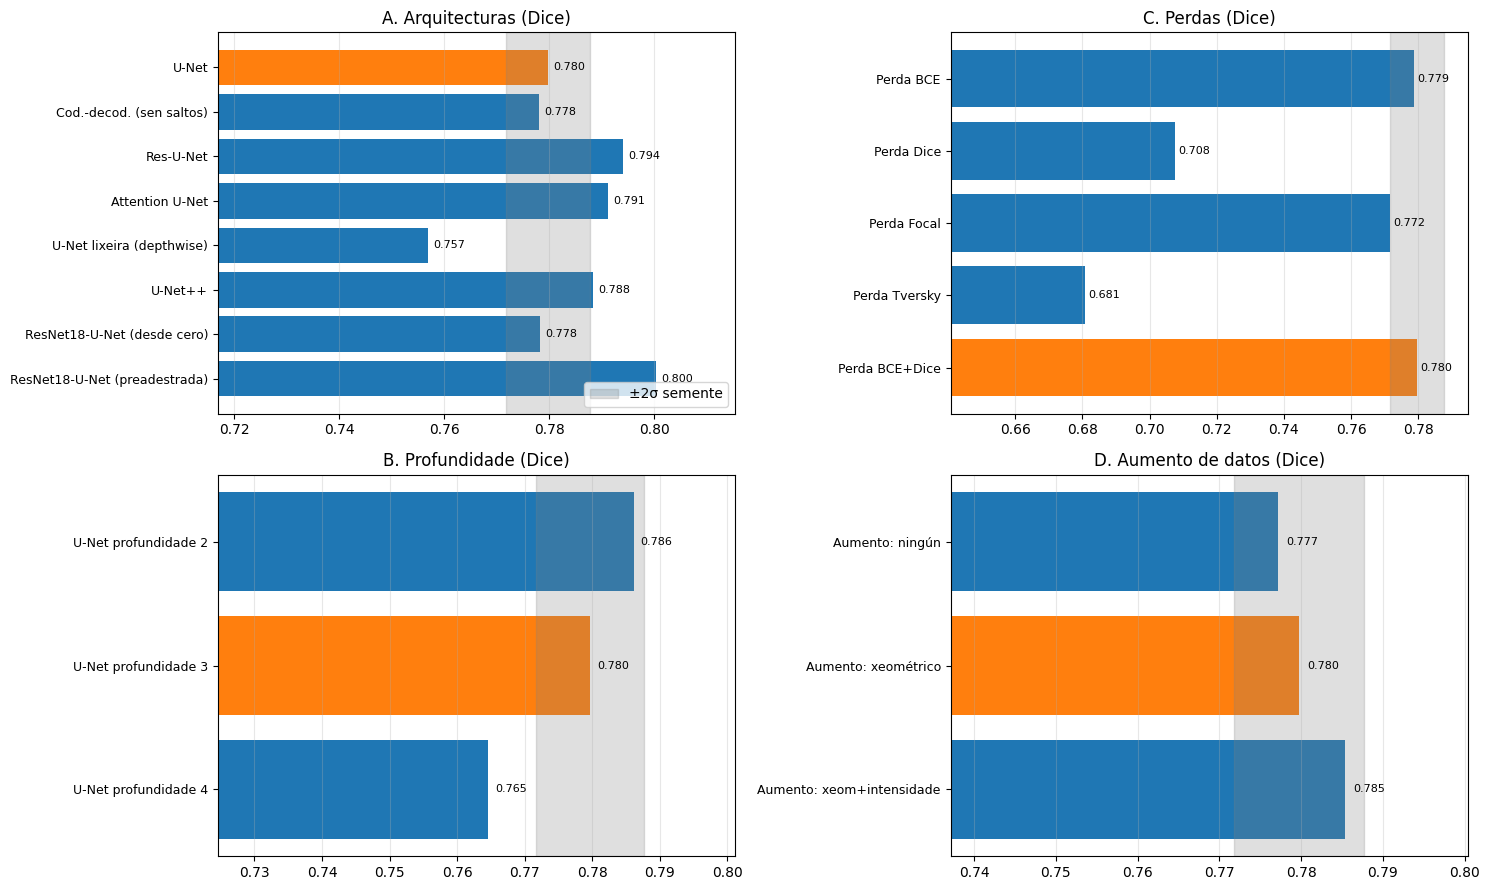

In [14]:
def barras(grupo, titulo, ref="U-Net", metrica="dice", ax=None, orde=None):
    nomes = [n for n, r in RES.items() if r["grupo"] == grupo]
    if orde: nomes = [n for n in orde if n in RES]
    v = [RES[n][metrica] for n in nomes]
    ax.barh(range(len(nomes)), v, color=["C1" if n == ref else "C0" for n in nomes])
    ax.axvspan(RES[ref][metrica] - 2 * RUIDO, RES[ref][metrica] + 2 * RUIDO, color="gray", alpha=0.25, label="±2σ semente")
    ax.set_yticks(range(len(nomes))); ax.set_yticklabels(nomes, fontsize=9); ax.invert_yaxis()
    lo = min(v + [RES[ref][metrica]]); ax.set_xlim(lo - 0.04, max(v + [RES[ref][metrica]]) + 0.015)
    for i, x in enumerate(v): ax.text(x + 0.001, i, f"{x:.3f}", va="center", fontsize=8)
    ax.set_title(titulo); ax.grid(alpha=0.3, axis="x")

fig, ax = plt.subplots(2, 2, figsize=(15, 9))
barras("A", "A. Arquitecturas (Dice)", ax=ax[0, 0])
barras("C", "C. Perdas (Dice)", ref="Perda BCE+Dice", ax=ax[0, 1])
barras("B", "B. Profundidade (Dice)", ref="U-Net profundidade 3", ax=ax[1, 0],
       orde=["U-Net profundidade 2", "U-Net profundidade 3", "U-Net profundidade 4"])
barras("D", "D. Aumento de datos (Dice)", ref="Aumento: xeométrico", ax=ax[1, 1],
       orde=["Aumento: ningún", "Aumento: xeométrico", "Aumento: xeom+intensidade"])
ax[0, 0].legend(loc="lower right")
plt.tight_layout(); plt.show()

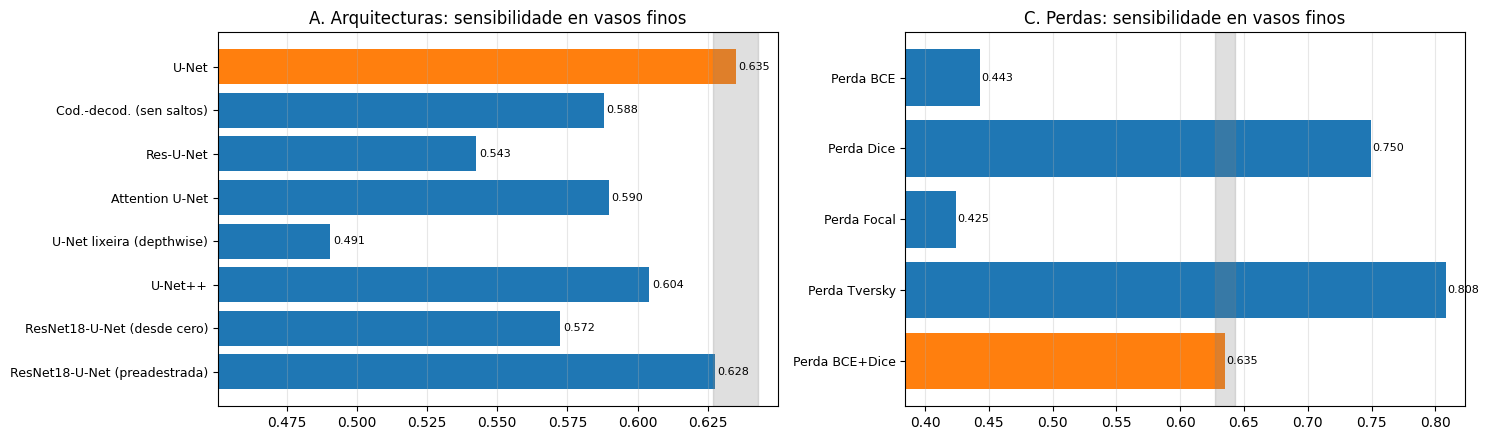

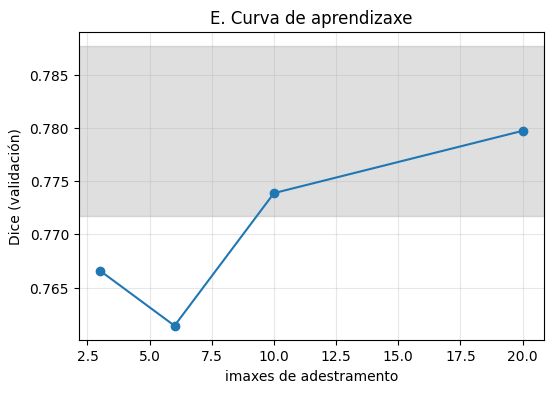

In [15]:
# Sensibilidade en vasos finos (a métrica clínica máis esixente) para arquitecturas e perdas
fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
barras("A", "A. Arquitecturas: sensibilidade en vasos finos", metrica="sens_fino", ax=ax[0])
barras("C", "C. Perdas: sensibilidade en vasos finos", ref="Perda BCE+Dice", metrica="sens_fino", ax=ax[1])
plt.tight_layout(); plt.show()

# Curva de aprendizaxe (bloque E)
nn_ = [3, 6, 10, 20]
dd = [RES[f"{n} imaxes de adestramento"]["dice"] for n in nn_]
plt.figure(figsize=(6, 4)); plt.plot(nn_, dd, "o-"); plt.xlabel("imaxes de adestramento"); plt.ylabel("Dice (validación)")
plt.axhspan(dd[-1] - 2 * RUIDO, dd[-1] + 2 * RUIDO, color="gray", alpha=0.25); plt.grid(alpha=0.3)
plt.title("E. Curva de aprendizaxe"); plt.show()

### Eficiencia: precisión fronte a custo

En moitos contextos clínicos (hardware limitado, tempo real, edge) non só importa o Dice, senón canto
custa conseguilo.

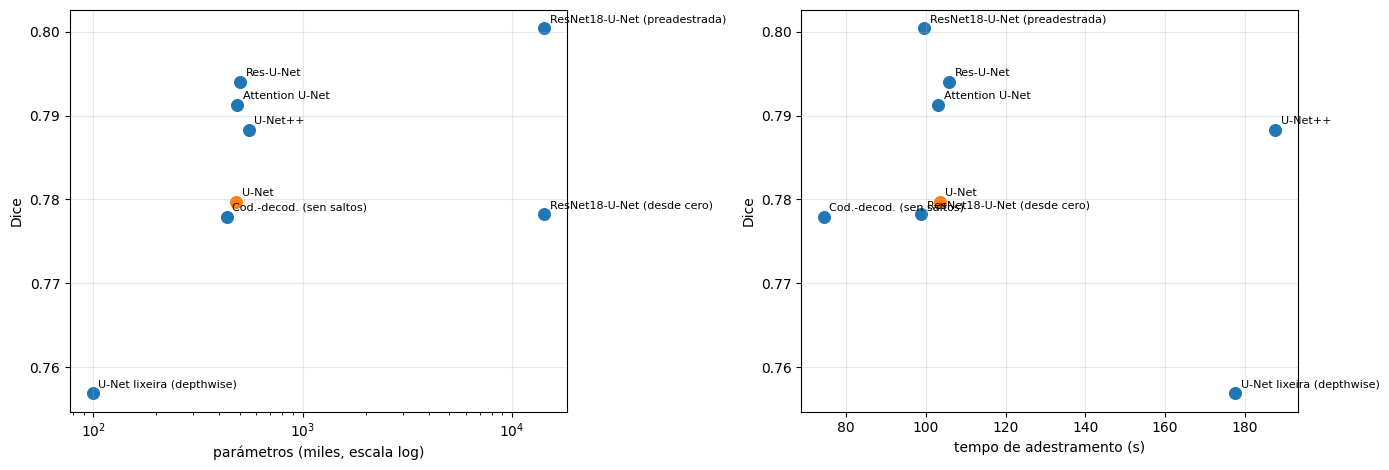

In [16]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.8))
for n, r in RES.items():
    if r["grupo"] != "A" and n != "U-Net": continue
    ax[0].scatter(r["params"] / 1e3, r["dice"], s=70, c="C1" if n == "U-Net" else "C0")
    ax[0].annotate(n, (r["params"] / 1e3, r["dice"]), fontsize=8, xytext=(4, 4), textcoords="offset points")
    ax[1].scatter(r["t_train"], r["dice"], s=70, c="C1" if n == "U-Net" else "C0")
    ax[1].annotate(n, (r["t_train"], r["dice"]), fontsize=8, xytext=(4, 4), textcoords="offset points")
ax[0].set_xscale("log"); ax[0].set_xlabel("parámetros (miles, escala log)"); ax[1].set_xlabel("tempo de adestramento (s)")
for a in ax: a.set_ylabel("Dice"); a.grid(alpha=0.3)
plt.tight_layout(); plt.show()

### Dice por imaxe

Un Dice medio oculta a variabilidade. Se dous modelos teñen medias parecidas pero un é consistente e o outro
falla en imaxes concretas, para un uso clínico importa moito.

/var/folders/26/f0r1bgyd67738k064bnrh4v40000gn/T/ipykernel_19078/2946013714.py:3: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot([RES[n]["dice_img"] for n in nomes], labels=[n.replace(" (", "\n(") for n in nomes], showmeans=True)


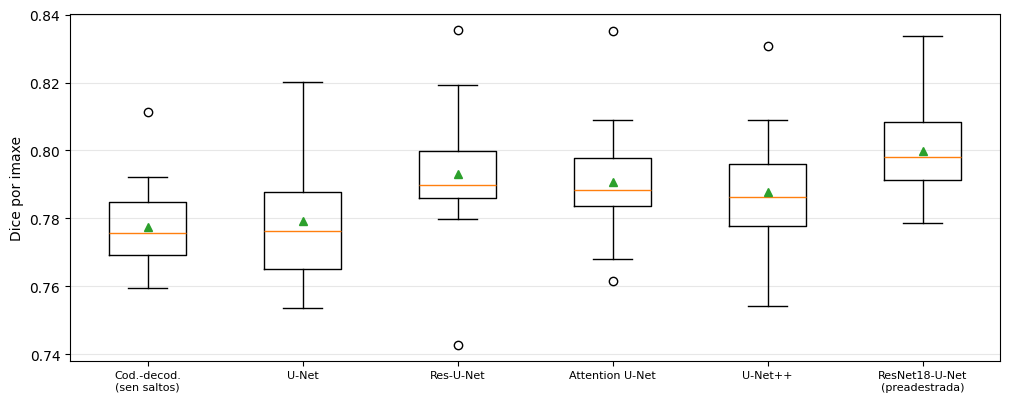

In [17]:
nomes = ["Cod.-decod. (sen saltos)", "U-Net", "Res-U-Net", "Attention U-Net", "U-Net++", "ResNet18-U-Net (preadestrada)"]
plt.figure(figsize=(12, 4.5))
plt.boxplot([RES[n]["dice_img"] for n in nomes], labels=[n.replace(" (", "\n(") for n in nomes], showmeans=True)
plt.ylabel("Dice por imaxe"); plt.grid(alpha=0.3, axis="y"); plt.xticks(fontsize=8); plt.show()

### Comparación visual (zoom)

Cadro de 200×200 da imaxe de validación 1. Verde = acerto, **vermello = falso positivo**, **azul = falso
negativo** (vasos que se perderon).

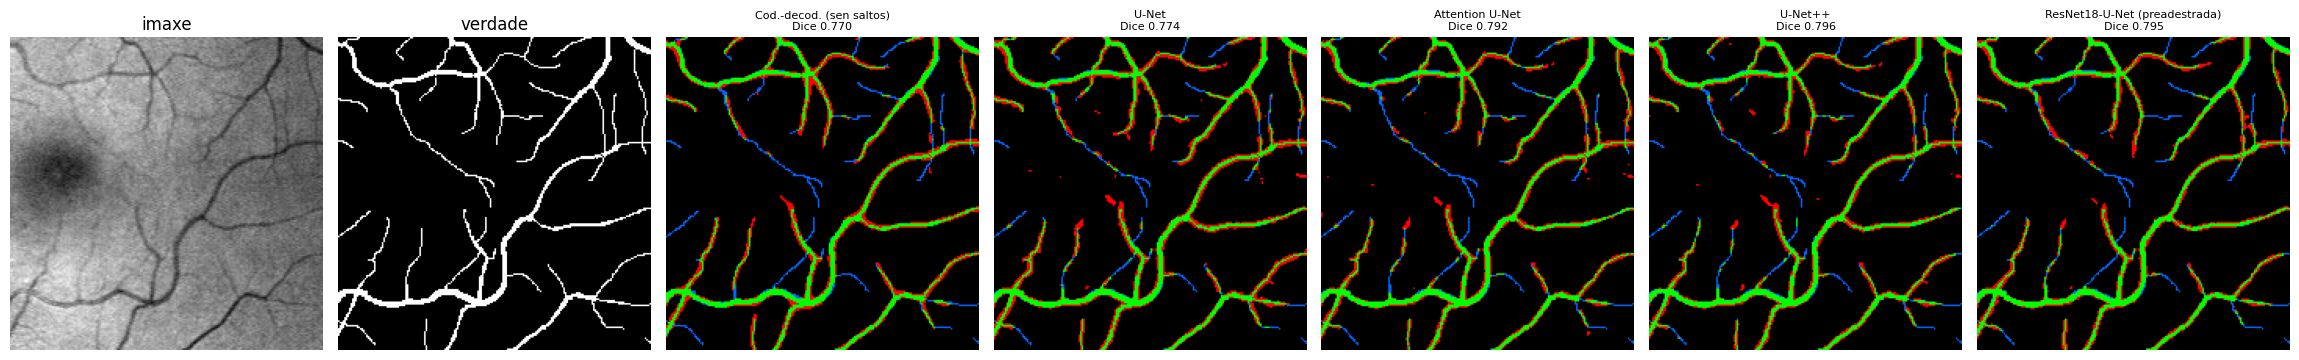

In [18]:
def overlay(prob, g, fov):
    p = (prob > 0.5) & fov
    o = np.zeros(g.shape + (3,)); o[p & g] = [0, 1, 0]; o[p & ~g] = [1, 0, 0]; o[~p & g] = [0, 0.4, 1]
    return o

n_img = 0
g = y_va[n_img, 0].bool().numpy(); fov = f_va[n_img, 0].numpy()
sl = (slice(200, 400), slice(250, 450))
mostrar = ["Cod.-decod. (sen saltos)", "U-Net", "Attention U-Net", "U-Net++", "ResNet18-U-Net (preadestrada)"]
fig, ax = plt.subplots(1, len(mostrar) + 2, figsize=(3.3 * (len(mostrar) + 2), 3.6))
ax[0].imshow(x_va[n_img, 0][sl], cmap="gray"); ax[0].set_title("imaxe")
ax[1].imshow(g[sl], cmap="gray"); ax[1].set_title("verdade")
for a, n in zip(ax[2:], mostrar):
    a.imshow(overlay(RES[n]["prob"][n_img, 0].float().numpy(), g, fov)[sl]); a.set_title(f"{n}\nDice {RES[n]['dice_img'][n_img]:.3f}", fontsize=8)
for a in ax: a.axis("off")
plt.tight_layout(); plt.show()

## 5. Lectura dos resultados

Esta cela escribe un resumo **a partir dos teus números** (non de resultados prefixados): para cada bloque
indica o mellor, e se a diferenza co valor de referencia supera ou non o ruído de semente.

In [19]:
def resumo(grupo, ref):
    nomes = [n for n, r in RES.items() if r["grupo"] == grupo]
    mellor = max(nomes, key=lambda n: RES[n]["dice"])
    d = RES[mellor]["dice"] - RES[ref]["dice"]
    if mellor == ref:
        veredicto = "a referencia é a mellor"
    else:
        veredicto = (f"gaña {d:+.3f} de Dice á referencia ({ref}) -> " +
                     ("DIFERENZA SUPERIOR ao ruído (>2σ)" if d > 2 * RUIDO and d > 0 else "dentro do ruído: NON concluínte"))
    print(f"[{grupo}] mellor: {mellor} (Dice {RES[mellor]['dice']:.3f}) | {veredicto}")

resumo("A", "U-Net"); resumo("B", "U-Net profundidade 3"); resumo("C", "Perda BCE+Dice")
resumo("D", "Aumento: xeométrico"); resumo("E", "20 imaxes de adestramento")
print(f"\nRuído de semente (σ): {RUIDO:.4f}")

[A] mellor: ResNet18-U-Net (preadestrada) (Dice 0.800) | gaña +0.021 de Dice á referencia (U-Net) -> DIFERENZA SUPERIOR ao ruído (>2σ)
[B] mellor: U-Net profundidade 2 (Dice 0.786) | gaña +0.006 de Dice á referencia (U-Net profundidade 3) -> dentro do ruído: NON concluínte
[C] mellor: Perda BCE+Dice (Dice 0.780) | a referencia é a mellor
[D] mellor: Aumento: xeom+intensidade (Dice 0.785) | gaña +0.006 de Dice á referencia (Aumento: xeométrico) -> dentro do ruído: NON concluínte
[E] mellor: 20 imaxes de adestramento (Dice 0.780) | a referencia é a mellor

Ruído de semente (σ): 0.0040


**Preguntas para discutir co grupo**

1. Que melloras superan o ruído de semente? Cales *parecían* melloras só por azar?
2. Compara o **custo** (parámetros, tempo) coa ganancia. Mereceu a pena a arquitectura máis complexa?
3. A rede preadestrada con **fotos naturais** axuda en retina? Por que podería funcionar aínda que as
   imaxes sexan distintas? (os primeiros filtros —bordos, texturas— son universais)
4. Que perda dá mellor **sensibilidade en vasos finos**? É a que escollerías clínicamente?
5. Con 3 imaxes anotadas aínda se consegue un Dice razoable? Que implica iso para un proxecto novo, onde
   cada anotación custa tempo de especialista?
6. Estas conclusións valen para **outro dataset** ou outra modalidade (TC, resonancia, microscopía)?
7. Que falta para sacar conclusións fiables: máis sementes? validación cruzada? un test externo?

**Limitacións deste estudo (importante dicilo)**

- Un orzamento **curto** (20 épocas): algunhas arquitecturas máis grandes poderían necesitar máis.
- **Mesmo `lr`** para todas, sen axustalo por modelo; unha comparación seria afinaría cada unha.
- Só 3 sementes para estimar o ruído (estimación pouco precisa).
- 20 imaxes de validación dun único dataset e un único observador como verdade.

## 6. Para probar

1. Sobe `EPOCAS` a 60. Cambia o orde dos modelos?
2. Mestura: **Attention + residual** (`UNet(bloque="res", salto="atencion")`).
3. Cambia `base=16` por `8` e `32` na U-Net. Como escalan o Dice e o tempo?
4. Proba un limiar distinto de 0.5 en cada modelo (a mellor perda pode ter o mellor limiar distinto).
5. Usa as 3 canles RGB como entrada (cambia `1` por `3` no primeiro bloque e quita o `expand` do ResNet).